# Phase 1 — Data Preparation & Customer-Snapshot Panel

**Project:** Temporal and Predictive Analytics for Data-Driven E-Commerce Decision Support (Group 8)
**Proposal sections:** 3.2 Dataset & Data Preparation · 3.3 Temporal Design · 3.6 Leakage Control

**Input:** `online_retail_II.xlsx` (UCI Online Retail II, raw, two yearly sheets)
**Outputs:**
- `data/interim/transactions_clean.parquet` — cleaned purchase lines, each with its `CancelDate` (NaT if never cancelled)
- `data/processed/customer_snapshot_panel.csv` / `.parquet` — one row per customer × snapshot (S1–S8) with RFM + behavioural features
- `outputs/tables/phase1_*.csv` — cleaning log, validation and summary tables

**Key design choice — snapshot-aware cancellations.** A purchase that is cancelled on date *d* still counts in every snapshot *t < d*, and is removed only from snapshots *t ≥ d*. Removing cancelled purchases globally (as a static cleaning does) would leak future information into earlier snapshots.

In [ ]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import (RAW_XLSX, GROUP_CLEAN_XLSX, INTERIM, PROCESSED, FIGURES, TABLES,
                    PRODUCT_STOCKCODE_PATTERN, SNAPSHOT_DATES, SNAPSHOT_ORDER, SNAPSHOT_INDEX,
                    RECENT_WINDOW_DAYS, RANDOM_STATE)

np.random.seed(RANDOM_STATE)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.width", 160)

## 1. Load the raw data
Reading the 45 MB Excel file is slow, so the combined raw table is cached as parquet after the first run.

In [2]:
RAW_CACHE = INTERIM / "raw_combined.parquet"

if RAW_CACHE.exists():
    raw = pd.read_parquet(RAW_CACHE)
else:
    sheets = pd.read_excel(RAW_XLSX, sheet_name=None)
    for name, df in sheets.items():
        print(f"{name:>16}: {len(df):>9,} rows | {df.InvoiceDate.min()} → {df.InvoiceDate.max()}")
    raw = pd.concat(sheets.values(), ignore_index=True)
    raw = raw.rename(columns={"Invoice": "InvoiceNo", "Customer ID": "CustomerID"})
    raw["InvoiceNo"] = raw["InvoiceNo"].astype(str)
    raw["StockCode"] = raw["StockCode"].astype(str)
    raw["Description"] = raw["Description"].astype(str)
    raw.to_parquet(RAW_CACHE, index=False)

print(f"Combined raw rows: {len(raw):,}")
raw.head()

Combined raw rows: 1,067,371


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


## 2. Cleaning (Section 3.2)

Steps, in order:
1. **Exact duplicates.** The two sheets overlap on 01–09 Dec 2010 (22,523 identical rows) and there are within-sheet duplicates; both are removed with `drop_duplicates()`.
2. **Missing CustomerID** — cannot be assigned to a customer state.
3. **Non-product rows** — StockCode must match `^\d{5}[A-Za-z]{0,2}$` (drops POST, DOT, M, C2, BANK CHARGES, ADJUST, AMAZONFEE, TEST, gift vouchers …).
4. **Split** into purchase lines (non-`C` invoice, Quantity > 0, Price > 0) and cancellation lines (`C` invoice, Quantity < 0). Bad-debt adjustments (`A` invoices, negative price) fall out here.

In [3]:
log = []
def step(name, df):
    log.append({"step": name, "rows": len(df),
                "customers": df["CustomerID"].nunique() if "CustomerID" in df else np.nan})
    return df

df = step("0. raw (both sheets)", raw.copy())
df = step("1. drop exact duplicates", df.drop_duplicates())
df = step("2. drop missing CustomerID", df.dropna(subset=["CustomerID"]))
df["CustomerID"] = df["CustomerID"].astype(int)
df = step("3. keep product StockCodes", df[df["StockCode"].str.match(PRODUCT_STOCKCODE_PATTERN)])

is_cancel = df["InvoiceNo"].str.startswith("C")
purchases = df[~is_cancel & (df["Quantity"] > 0) & (df["Price"] > 0)].reset_index(drop=True)
cancels = df[is_cancel & (df["Quantity"] < 0)].reset_index(drop=True)
step("4a. purchase lines (qty>0, price>0)", purchases)
step("4b. cancellation lines", cancels)

purchases["Revenue"] = purchases["Quantity"] * purchases["Price"]
cleaning_log = pd.DataFrame(log)
cleaning_log

,step,rows,customers
0,0. raw (both sheets),1067371,5942
1,1. drop exact duplicates,1033036,5942
2,2. drop missing CustomerID,797885,5942
3,3. keep product StockCodes,794223,5876
4,"4a. purchase lines (qty>0, price>0)",776577,5852
5,4b. cancellation lines,17586,2444


## 3. Snapshot-aware cancellation matching

Each cancellation line is matched **one-to-one** to an earlier purchase line with the same `CustomerID`, `StockCode` and `Quantity` (first-in-first-out: the **earliest** still-unmatched purchase on or before the cancellation date). The matched purchase gets `CancelDate` = cancellation date.

- Purchase counts in snapshot *t* ⇔ `InvoiceDate ≤ t` **and** (`CancelDate` is NaT **or** `CancelDate > t`).
- Cancellations with no exact match (partial-quantity cancellations, or cancellations of purchases made before Dec 2009) are not applied. This matches the group's original cleaning rule and is reported below as a limitation.

In [4]:
def match_cancellations(purchases: pd.DataFrame, cancels: pd.DataFrame) -> pd.Series:
    """Return a CancelDate for each purchase line (NaT if never cancelled)."""
    p = purchases[["CustomerID", "StockCode", "Quantity", "InvoiceDate"]].assign(line_id=np.arange(len(purchases)))
    c = cancels[["CustomerID", "StockCode", "Quantity", "InvoiceDate"]].assign(
        cancel_id=np.arange(len(cancels)), Quantity=-cancels["Quantity"])
    cand = c.merge(p, on=["CustomerID", "StockCode", "Quantity"], suffixes=("_c", "_p"))
    cand = cand[cand["InvoiceDate_p"] <= cand["InvoiceDate_c"]]
    # process cancellations chronologically; each takes the earliest still-unmatched purchase (FIFO)
    cand = cand.sort_values(["InvoiceDate_c", "cancel_id", "InvoiceDate_p"], ascending=[True, True, True])
    used, cancel_date, matched_cancels = set(), {}, set()
    for cid, g in cand.groupby("cancel_id", sort=False):
        for lid, dc in zip(g["line_id"].values, g["InvoiceDate_c"].values):
            if lid not in used:
                used.add(lid); cancel_date[lid] = dc; matched_cancels.add(cid)
                break
    out = pd.Series(pd.NaT, index=purchases.index, dtype="datetime64[ns]")
    out.loc[list(cancel_date)] = list(cancel_date.values())
    return out, np.array(sorted(matched_cancels))

purchases["CancelDate"], matched_ids = match_cancellations(purchases, cancels)
unmatched = cancels.drop(index=matched_ids)

lag_days = (purchases["CancelDate"] - purchases["InvoiceDate"]).dt.days.dropna()
cancel_summary = pd.Series({
    "cancellation lines": len(cancels),
    "matched to an earlier purchase": len(matched_ids),
    "unmatched (not applied)": len(unmatched),
    "unmatched value (£)": (-unmatched["Quantity"] * unmatched["Price"]).sum(),
    "matched purchase value (£)": purchases.loc[purchases.CancelDate.notna(), "Revenue"].sum(),
    "total purchase value (£)": purchases["Revenue"].sum(),
    "median purchase→cancel lag (days)": lag_days.median(),
    "share cancelled >90 days later": (lag_days > 90).mean(),
})
cancel_summary.to_frame("value")

,value
cancellation lines,"17,586.00"
matched to an earlier purchase,"6,227.00"
unmatched (not applied),"11,359.00"
unmatched value (£),"157,254.89"
matched purchase value (£),"570,200.32"
total purchase value (£),"17,068,567.97"
median purchase→cancel lag (days),18.00
share cancelled >90 days later,0.22


## 4. Validation against the group's static cleaned file
After applying **all** cancellations (i.e. the view at the end of the data), our table should reproduce `online_retail_II_cleaned.xlsx`.

In [5]:
final_view = purchases[purchases["CancelDate"].isna()]
validation = {"ours (after all cancellations)": (len(final_view), final_view.CustomerID.nunique(),
                                                 final_view.Revenue.sum())}
GROUP_CACHE = INTERIM / "group_cleaned.parquet"
if GROUP_CLEAN_XLSX.exists():
    if GROUP_CACHE.exists():
        grp = pd.read_parquet(GROUP_CACHE)
    else:
        grp = pd.read_excel(GROUP_CLEAN_XLSX)
        grp.astype({"StockCode": str, "Description": str, "InvoiceDate": str}).to_parquet(GROUP_CACHE, index=False)
    validation["group cleaned file"] = (len(grp), grp["CustomerID"].nunique(), grp["Revenue"].sum())
validation = pd.DataFrame(validation, index=["rows", "customers", "revenue (£)"]).T
if len(validation) == 2:
    validation.loc["difference"] = validation.iloc[0] - validation.iloc[1]
validation

,rows,customers,revenue (£)
ours (after all cancellations),"770,350.00","5,839.00","16,498,367.65"
group cleaned file,"770,306.00","5,839.00","16,495,177.20"
difference,44.00,0.00,"3,190.45"


With FIFO one-to-one matching, the end-of-data view reproduces the group's file almost exactly: every row of the group file is present in ours, and ours has 44 extra lines (≈0.006 %). The static cleaning most likely let one cancellation remove more than one identical purchase line; we keep the stricter one-to-one rule. Customer counts are identical. (A last-in-first-out rule was also tested and gave ~1,400 line-level differences, so FIFO is the rule the group's file was built with.)

**Why the static file is not used directly:** it removes later-cancelled purchases from *all* periods. The table below counts, for each snapshot, the purchase lines that the static file would already have removed although their cancellation had not happened yet — information the retailer did not have at that date.

In [6]:
leak_rows = []
for s, t in SNAPSHOT_DATES.items():
    t_end = t + pd.Timedelta(days=1)
    seen = purchases["InvoiceDate"] < t_end
    cancelled_later = purchases["CancelDate"].notna() & (purchases["CancelDate"] >= t_end)
    leak_rows.append({"snapshot": s, "date": t.date(),
                      "purchase lines visible at t": int(seen.sum()),
                      "lines cancelled only after t": int((seen & cancelled_later).sum()),
                      "customers affected": purchases.loc[seen & cancelled_later, "CustomerID"].nunique()})
leakage_check = pd.DataFrame(leak_rows)
leakage_check

,snapshot,date,purchase lines visible at t,lines cancelled only after t,customers affected
0,S1,2010-03-31,106179,626,257
1,S2,2010-06-30,191645,702,295
2,S3,2010-09-30,278137,894,308
3,S4,2010-12-31,410996,770,256
4,S5,2011-03-31,478272,747,251
5,S6,2011-06-30,555397,644,208
6,S7,2011-09-30,648064,533,166
7,S8,2011-12-09,776577,0,0


## 5. Customer-snapshot panel (Section 3.3)

For each snapshot date *t* (inclusive, end of day) and each customer with ≥ 1 valid purchase up to *t*:

| Feature | Definition | Used for |
|---|---|---|
| `Recency` | days from last valid purchase to *t* | clustering + prediction |
| `Frequency` | number of distinct invoices (cumulative) | clustering + prediction |
| `Monetary` | total revenue £ (cumulative) | clustering + prediction |
| `AOV` | Monetary / Frequency | prediction / profiling |
| `ProductVariety` | number of distinct StockCodes | prediction / profiling |
| `Tenure` | days from first valid purchase to *t* | prediction / profiling |
| `RecentOrders` | distinct invoices in the last 90 days before *t* | prediction / profiling |
| `RecentSpend` | revenue £ in the last 90 days before *t* | prediction / profiling |

Customers stay in the panel after they stop buying (cumulative RFM), so inactivity shows up as growing Recency — as stated in the proposal.

In [7]:
def build_snapshot(purchases: pd.DataFrame, snap: str, t: pd.Timestamp) -> pd.DataFrame:
    t_end = t + pd.Timedelta(days=1)                      # include the whole snapshot day
    valid = purchases[(purchases["InvoiceDate"] < t_end) &
                      (purchases["CancelDate"].isna() | (purchases["CancelDate"] >= t_end))]
    g = valid.groupby("CustomerID")
    out = pd.DataFrame({
        "first_purchase": g["InvoiceDate"].min(),
        "last_purchase": g["InvoiceDate"].max(),
        "Frequency": g["InvoiceNo"].nunique(),
        "Monetary": g["Revenue"].sum(),
        "ProductVariety": g["StockCode"].nunique(),
        "Country": g["Country"].agg(lambda s: s.mode().iat[0]),
    })
    recent = valid[valid["InvoiceDate"] >= t_end - pd.Timedelta(days=RECENT_WINDOW_DAYS)].groupby("CustomerID")
    out["RecentOrders"] = recent["InvoiceNo"].nunique()
    out["RecentSpend"] = recent["Revenue"].sum()
    out[["RecentOrders", "RecentSpend"]] = out[["RecentOrders", "RecentSpend"]].fillna(0)
    out["Recency"] = (t.normalize() - out["last_purchase"].dt.normalize()).dt.days
    out["Tenure"] = (t.normalize() - out["first_purchase"].dt.normalize()).dt.days
    out["AOV"] = out["Monetary"] / out["Frequency"]
    out.insert(0, "snapshot", snap)
    out.insert(1, "t", SNAPSHOT_INDEX[snap])
    out.insert(2, "snapshot_date", t)
    return out.reset_index()

panel = pd.concat([build_snapshot(purchases, s, t) for s, t in SNAPSHOT_DATES.items()], ignore_index=True)
FEATURES = ["Recency", "Frequency", "Monetary", "AOV", "ProductVariety", "Tenure", "RecentOrders", "RecentSpend"]
panel = panel[["CustomerID", "snapshot", "t", "snapshot_date", *FEATURES, "Country", "first_purchase", "last_purchase"]]
panel["RecentOrders"] = panel["RecentOrders"].astype(int)
print(f"Panel: {len(panel):,} customer-snapshot rows, {panel.CustomerID.nunique():,} customers")
panel.head()

Panel: 33,842 customer-snapshot rows, 5,843 customers


,CustomerID,snapshot,t,snapshot_date,Recency,Frequency,Monetary,AOV,ProductVariety,Tenure,RecentOrders,RecentSpend,Country,first_purchase,last_purchase
0,12346,S1,1,2010-03-31,29,1,27.05,27.05,5,29,1,27.05,United Kingdom,2010-03-02 13:08:00,2010-03-02 13:08:00
1,12358,S1,1,2010-03-31,113,1,"1,429.83","1,429.83",17,113,0,0.00,Austria,2009-12-08 07:59:00,2009-12-08 07:59:00
2,12359,S1,1,2010-03-31,8,4,"1,444.03",361.01,63,116,2,683.34,Cyprus,2009-12-05 13:32:00,2010-03-23 08:55:00
3,12360,S1,1,2010-03-31,37,1,118.00,118.00,10,37,1,118.00,Austria,2010-02-22 09:32:00,2010-02-22 09:32:00
4,12361,S1,1,2010-03-31,64,1,94.20,94.20,6,64,1,94.20,Belgium,2010-01-26 14:37:00,2010-01-26 14:37:00


## 6. Panel checks

In [8]:
# (a) uniqueness and no future information
assert not panel.duplicated(["CustomerID", "snapshot"]).any()
assert (panel["last_purchase"] < panel["snapshot_date"] + pd.Timedelta(days=1)).all()
assert (panel["Recency"] >= 0).all() and (panel["Tenure"] >= panel["Recency"]).all()

# (b) customers per snapshot, new entrants and recently active share
per_snap = panel.groupby("snapshot").agg(
    date=("snapshot_date", "first"), customers=("CustomerID", "nunique"),
    active_last_90d=("RecentOrders", lambda s: (s > 0).sum()),
    median_recency=("Recency", "median"), median_frequency=("Frequency", "median"),
    median_monetary=("Monetary", "median")).reindex(SNAPSHOT_ORDER)
per_snap["new_customers"] = per_snap["customers"].diff().fillna(per_snap["customers"]).astype(int)
per_snap["active_share"] = per_snap["active_last_90d"] / per_snap["customers"]
per_snap

,date,customers,active_last_90d,median_recency,median_frequency,median_monetary,new_customers,active_share
snapshot,,,,,,,,
S1,2010-03-31,2132,1780,31.00,1.00,429.23,2132,0.83
S2,2010-06-30,2946,2013,51.00,2.00,538.80,814,0.68
S3,2010-09-30,3531,2020,66.00,2.00,611.32,585,0.57
S4,2010-12-31,4303,2639,68.00,2.00,701.62,772,0.61
S5,2011-03-31,4680,1772,128.00,2.00,703.84,377,0.38
S6,2011-06-30,5007,1962,144.00,3.00,746.24,327,0.39
S7,2011-09-30,5404,2145,147.00,3.00,777.57,397,0.40
S8,2011-12-09,5839,2877,95.00,3.00,851.01,435,0.49


In [9]:
# (c) observations available for each transition t -> t+1 and for history-eligible origins (Config A/B)
trans = []
for i, s in enumerate(SNAPSHOT_ORDER[:-1]):
    nxt = SNAPSHOT_ORDER[i + 1]
    ids_t = set(panel.loc[panel.snapshot == s, "CustomerID"])
    ids_n = set(panel.loc[panel.snapshot == nxt, "CustomerID"])
    hist = set(panel.loc[panel.snapshot == SNAPSHOT_ORDER[i - 2], "CustomerID"]) if i >= 2 else set()
    trans.append({"transition": f"{s}→{nxt}", "origins at t": len(ids_t),
                  "with target at t+1": len(ids_t & ids_n),
                  "history-eligible (seen at t-2)": len(ids_t & hist) if i >= 2 else 0,
                  "split": "train" if s in ["S1","S2","S3","S4","S5"] else "test"})
transitions_available = pd.DataFrame(trans)
transitions_available

,transition,origins at t,with target at t+1,history-eligible (seen at t-2),split
0,S1→S2,2132,2132,0,train
1,S2→S3,2946,2946,0,train
2,S3→S4,3531,3530,2132,train
3,S4→S5,4303,4303,2946,train
4,S5→S6,4680,4680,3530,train
5,S6→S7,5007,5007,4303,test
6,S7→S8,5404,5401,4680,test


Because the panel is cumulative, almost every customer seen at *t* is also present at *t+1*. The few exceptions are customers whose **all** purchases were cancelled later (4 customers); they have no target and are excluded from the prediction dataset. Config A/B use only the history-eligible origins (S3 onwards).

In [10]:
# (d) skewness of the clustering inputs — informs the log transform in Phase 2
skew = panel.groupby("snapshot")[["Recency", "Frequency", "Monetary"]].skew().reindex(SNAPSHOT_ORDER)
skew_log = panel.assign(**{c: np.log1p(panel[c]) for c in ["Recency", "Frequency", "Monetary"]}) \
                .groupby("snapshot")[["Recency", "Frequency", "Monetary"]].skew().reindex(SNAPSHOT_ORDER)
pd.concat({"raw skew": skew, "log1p skew": skew_log}, axis=1)

raw skew                    log1p skew                   
          Recency Frequency Monetary    Recency Frequency Monetary
snapshot                                                          
S1           0.79      7.27    18.48      -0.86      1.89     0.44
S2           0.91      7.60    19.62      -1.00      1.52     0.24
S3           0.85      8.72    23.08      -0.88      1.32     0.24
S4           1.29      9.91    24.37       0.04      1.17     0.24
S5           0.90      9.80    24.10      -1.19      1.13     0.25
S6           0.76     10.14    25.02      -1.03      1.08     0.25
S7           0.70     10.77    25.50      -0.92      1.05     0.27
S8           0.89     11.97    26.68      -0.55      1.00     0.24

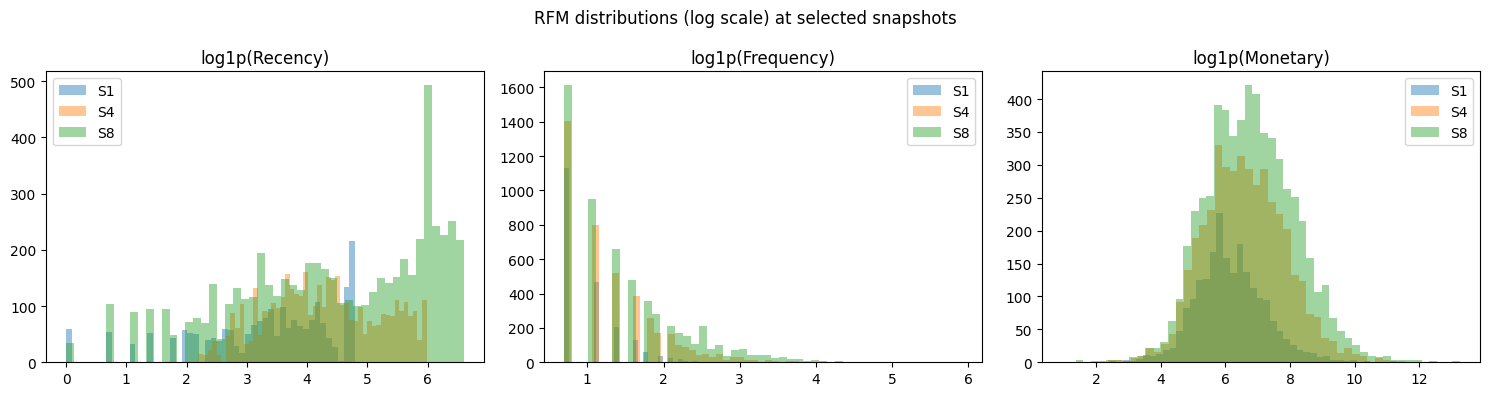

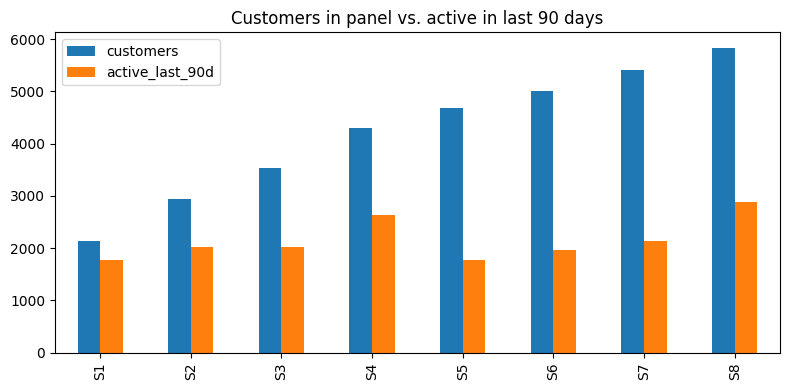

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    for s in ["S1", "S4", "S8"]:
        ax.hist(np.log1p(panel.loc[panel.snapshot == s, col]), bins=50, alpha=0.45, label=s)
    ax.set_title(f"log1p({col})"); ax.legend()
fig.suptitle("RFM distributions (log scale) at selected snapshots")
fig.tight_layout(); fig.savefig(FIGURES / "phase1_rfm_distributions.png", dpi=150)

fig, ax = plt.subplots(figsize=(8, 4))
per_snap[["customers", "active_last_90d"]].plot(kind="bar", ax=ax)
ax.set_title("Customers in panel vs. active in last 90 days"); ax.set_xlabel("")
fig.tight_layout(); fig.savefig(FIGURES / "phase1_customers_per_snapshot.png", dpi=150)

## 7. Save outputs

In [12]:
purchases.to_parquet(INTERIM / "transactions_clean.parquet", index=False)
panel.to_parquet(PROCESSED / "customer_snapshot_panel.parquet", index=False)
panel.to_csv(PROCESSED / "customer_snapshot_panel.csv", index=False)

cleaning_log.to_csv(TABLES / "phase1_cleaning_log.csv", index=False)
cancel_summary.to_frame("value").to_csv(TABLES / "phase1_cancellation_summary.csv")
validation.to_csv(TABLES / "phase1_validation_vs_group_file.csv")
leakage_check.to_csv(TABLES / "phase1_snapshot_aware_check.csv", index=False)
per_snap.to_csv(TABLES / "phase1_panel_per_snapshot.csv")
transitions_available.to_csv(TABLES / "phase1_transitions_available.csv", index=False)
print("Saved:", *sorted(p.name for p in [*PROCESSED.iterdir(), *TABLES.iterdir()]), sep="\n  ")

Saved:
  customer_snapshot_panel.csv
  customer_snapshot_panel.parquet
  k_selection_raw
  panel_with_states.csv
  panel_with_states.parquet
  phase1_cancellation_summary.csv
  phase1_cleaning_log.csv
  phase1_panel_per_snapshot.csv
  phase1_snapshot_aware_check.csv
  phase1_transitions_available.csv
  phase1_validation_vs_group_file.csv
  phase2_centroids.csv
  phase2_k_selection.csv
  phase2_k_selection_robustness.csv
  phase2_state_distribution.csv
  phase2_state_drift_check.csv
  phase2_state_profiles.csv
  phase3_entry_states.csv
  phase3_markov_order_test_train.csv
  phase3_persistence_by_transition.csv
  phase3_target_distribution.csv
  phase3_time_homogeneity.csv
  phase3_top_movements.csv
  phase3_transition_matrix.csv
  phase3_tuning_folds.csv
  phase4_best_params.csv
  phase4_delta_point_estimates.csv
  phase4_per_class.csv
  phase4_permutation_importance.csv
  phase4_test_by_origin.csv
  phase4_test_predictions.parquet
  phase4_test_results.csv
  phase4_tuning_folds.csv
  p

## Summary & hand-off to Phase 2

- The cleaned transaction table keeps every purchase together with its `CancelDate`, so any snapshot can be rebuilt without look-ahead.
- `customer_snapshot_panel` is the single input for Phase 2 (K-Means states on R, F, M only — fitted on training snapshots, then frozen) and Phase 3 (transition matrix, lagged states, state duration).
- Limitations to report: unmatched cancellations (partial quantities / pre-period purchases) are not applied; cumulative Frequency and Monetary grow mechanically over time (Section 3.8); S7→S8 is a shorter interval (≈ 2.3 months).